# Validação Física e Eventos Estocásticos — Marco M3 (`physics.py` e `events.py`)

Este notebook documenta e valida visualmente os subsistemas do **Marco M3** (`docs/fisica.md`, Seções 3, 4 e 5), distinguindo explicitamente o que vem da literatura/estatística histórica/dados D4 do que é hipótese de modelagem:

| Subsistema | O que vem da Literatura / Regras / Dados | O que é Escolha / Hipótese de Modelagem |
|---|---|---|
| **Ar Sujo (Seção 3)** | Faixa de penalidade máxima `0,35–0,50 s/volta` a 1 *car-length* e perda integrada de *downforce* de `12%` (Traffic Eng. Journal [14]); forma exponencial (arXiv:2503.05421 [17]). | Constante de decaimento temporal $\lambda = 0,65\text{ s}$ e corte em $3,0\text{ s}$ (parametrizados para concentrar o efeito abaixo de $1\text{ s}$ e torná-lo residual acima de $2\text{ s}$). |
| **DRS (Seção 4)** | Regra FIA (`gap < 1,0 s`, pista seca, bandeira verde, bloqueio na largada/relargada [22][23]); zonas `drs_activation` anotadas em `track_maps/*.json` (Contrato D4); referência de ganho `0,436 s` em Hockenheim [21] e $\Delta v \approx 10\text{–}12\text{ km/h}$ a $80\text{ m/s}$ [18][20]. | Taxa linear de 1ª ordem $\gamma_{\text{DRS}} = 0,00045\text{ s/m}$ uniforme entre os circuitos. |
| **Acidentes NHPP e SC/VSC (Seção 5)** | Frequência histórica da temporada 2022: **1,09 SC/corrida** (24 em 22 GPs) e **0,95 VSC/corrida** (21 em 22 GPs), duração típica de 2–3 voltas de SC e 0–2 de VSC (Auto Motor und Sport [25], F1 Wiki [26]); geometria 2D (`points`) e zonas `braking_zone` / `runoff` do Contrato D4. | Pesos relativos de frenagem ($w_{\text{braking}}$), multiplicadores de clima/aderência e coeficientes logísticos ($\alpha_0, \alpha_{\text{runoff}}, \alpha_{\text{severity}}$) — **hipóteses de modelagem** calibradas para reproduzir a frequência agregada de 2022 sem dataset de coordenadas de colisão. |

In [1]:
%matplotlib inline
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

backend_dir = Path("../../backend").resolve()
if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

from app.models.track import TrackMap
from sim.events import (
    SafetyCarStateMachine,
    build_track_risk_profile,
    sample_driver_lap_incident,
)
from sim.physics import (
    dirty_air_time_delta,
    drs_lap_time_gain,
)

interlagos = TrackMap.load(Path("../../track_maps/interlagos.json"))
monza = TrackMap.load(Path("../../track_maps/monza.json"))
monaco = TrackMap.load(Path("../../track_maps/monaco.json"))
print("Circuitos D4 carregados:", interlagos.circuit_id, monza.circuit_id, monaco.circuit_id)


Circuitos D4 carregados: interlagos monza monaco


## 1. Efeito de Ar Sujo (Seção 3) e Ganho de DRS por Circuito (Seção 4)

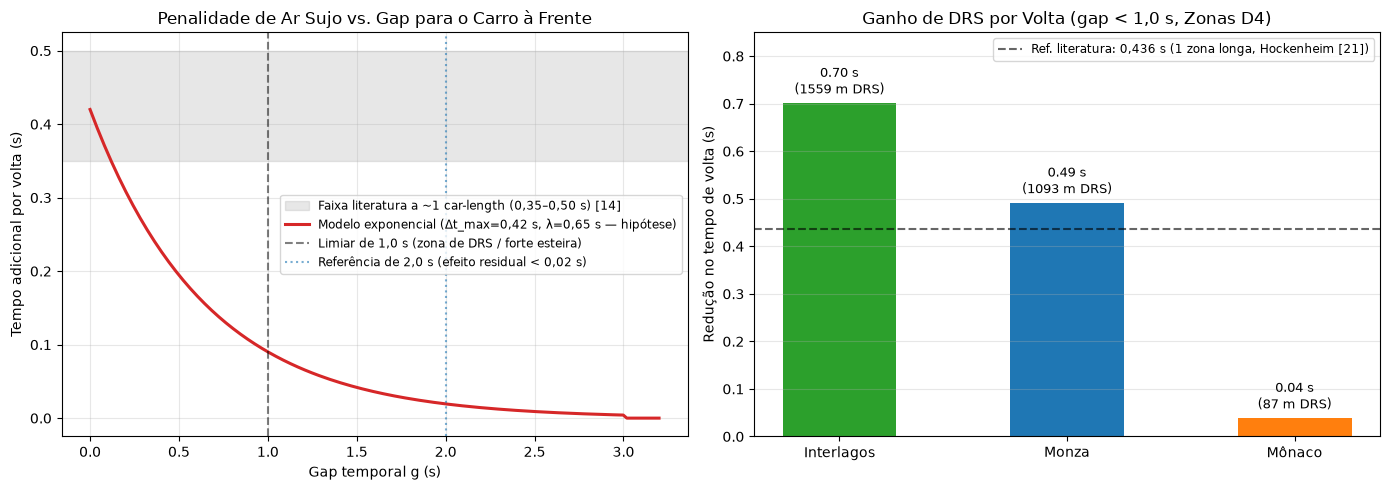

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

gaps = np.linspace(0.0, 3.2, 160)
penalties = [dirty_air_time_delta(float(g)) for g in gaps]

ax1.axhspan(0.35, 0.50, color="tab:gray", alpha=0.18, label="Faixa literatura a ~1 car-length (0,35–0,50 s) [14]")
ax1.plot(gaps, penalties, color="tab:red", lw=2.2, label="Modelo exponencial (Δt_max=0,42 s, λ=0,65 s — hipótese)")
ax1.axvline(1.0, color="black", ls="--", alpha=0.5, label="Limiar de 1,0 s (zona de DRS / forte esteira)")
ax1.axvline(2.0, color="tab:blue", ls=":", alpha=0.6, label="Referência de 2,0 s (efeito residual < 0,02 s)")
ax1.set_title("Penalidade de Ar Sujo vs. Gap para o Carro à Frente")
ax1.set_xlabel("Gap temporal g (s)")
ax1.set_ylabel("Tempo adicional por volta (s)")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8.5)

tracks = [("Interlagos", interlagos), ("Monza", monza), ("Mônaco", monaco)]
names = [t[0] for t in tracks]
drs_lengths = [sum(z.length_m for z in t[1].zones if z.type == "drs_activation") for t in tracks]
drs_gains = [drs_lap_time_gain(t[1], gap_ahead_s=0.6, current_lap=10) for t in tracks]

bars = ax2.bar(names, drs_gains, color=["tab:green", "tab:blue", "tab:orange"], width=0.5)
ax2.axhline(0.436, color="black", ls="--", alpha=0.6, label="Ref. literatura: 0,436 s (1 zona longa, Hockenheim [21])")
for bar, length_m, gain_s in zip(bars, drs_lengths, drs_gains):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        gain_s + 0.02,
        f"{gain_s:.2f} s\n({length_m:.0f} m DRS)",
        ha="center",
        fontsize=9,
    )
ax2.set_ylim(0, 0.85)
ax2.set_title("Ganho de DRS por Volta (gap < 1,0 s, Zonas D4)")
ax2.set_ylabel("Redução no tempo de volta (s)")
ax2.grid(axis="y", alpha=0.3)
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.savefig("validacao_ar_sujo_drs.png", dpi=130)
plt.show()


## 2. Distribuição Espacial 1D e Calibração de SC/VSC por Circuito (Seção 5)

Distinção metodológica essencial entre **ajuste reverso da média** e **diferenciação emergente entre pistas** (100 corridas simuladas, 20 carros $\times$ 58 voltas):
- **Ajuste reverso (hipótese calibrada na média)**: A intensidade base $\lambda_{base} = 2,4 \times 10^{-7}\text{ m}^{-1}$ e os pesos $w_{braking} \in \{6, 11, 18\}$ foram escolhidos para que a média global das 3 pistas reproduza a ordem de grandeza da temporada 2022 da F1 ($\approx 1,09\text{ SC}$ e $\approx 0,95\text{ VSC}$ por corrida, Auto Motor und Sport [25]) e concentre ~65–75% dos incidentes nas zonas de frenagem.
- **Diferenciação emergente via Contrato D4**: Mantendo os **mesmos** parâmetros globais em todas as pistas, a variação entre circuitos no gráfico da direita (`Mônaco > Interlagos > Monza` em Safety Car pleno) emerge exclusivamente da geometria D4 anotada (`runoff: muro` em Mônaco vs. `asfalto/brita` em Interlagos e Monza).


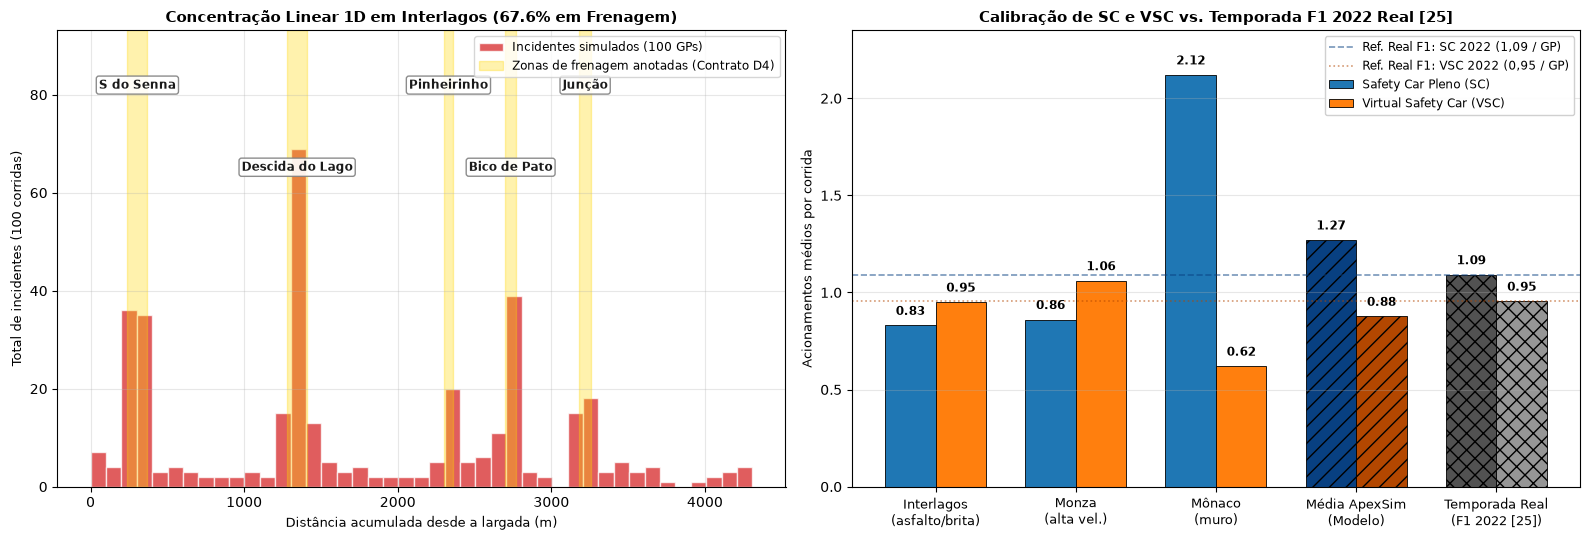

In [3]:
n_races = 100
n_laps = 58
n_drivers = 20

def simulate_100_races(track: TrackMap, seed: int = 2024):
    r = random.Random(seed)
    incidents, sc_list, vsc_list = [], [], []
    for _ in range(n_races):
        sm = SafetyCarStateMachine()
        for lap in range(1, n_laps + 1):
            lap_incs = []
            if sm.state == "GREEN":
                for d in range(n_drivers):
                    inc = sample_driver_lap_incident(
                        f"D{d:02d}", lap, track, r, grip_factor=0.88, weather="seco", aggression=0.5
                    )
                    if inc is not None:
                        incidents.append(inc)
                        lap_incs.append(inc)
            sm.trigger_from_incidents(lap_incs, r)
            sm.advance_lap()
        sc_list.append(sm.sc_deployments)
        vsc_list.append(sm.vsc_deployments)
    return incidents, sc_list, vsc_list

inc_inter, sc_inter, vsc_inter = simulate_100_races(interlagos, 2024)
inc_monza, sc_monza, vsc_monza = simulate_100_races(monza, 2025)
inc_monaco, sc_monaco, vsc_monaco = simulate_100_races(monaco, 2026)

braking_ratio = sum(1 for i in inc_inter if i.is_braking_zone) / len(inc_inter)

fig, (ax_map, ax_sc) = plt.subplots(1, 2, figsize=(16, 5.5))

# ----------------- Painel Esquerdo: Histograma 1D -----------------
distances = [i.distance_m for i in inc_inter]
counts, _, _ = ax_map.hist(
    distances,
    bins=43,
    range=(0, interlagos.length_m),
    color="#d62728",
    alpha=0.75,
    edgecolor="white",
    label="Incidentes simulados (100 GPs)",
)
ymax = max(counts) * 1.35
ax_map.set_ylim(0, ymax)

first_bz = True
corner_stagger = {
    "S do Senna": (ymax * 0.88, "#1a1a1a"),
    "Descida do Lago": (ymax * 0.70, "#1a1a1a"),
    "Pinheirinho": (ymax * 0.88, "#1a1a1a"),
    "Bico de Pato": (ymax * 0.70, "#1a1a1a"),
    "Junção": (ymax * 0.88, "#1a1a1a"),
}

for seg in build_track_risk_profile(interlagos):
    if seg.is_braking_zone:
        lbl = "Zonas de frenagem anotadas (Contrato D4)" if first_bz else None
        first_bz = False
        ax_map.axvspan(seg.start_m, seg.end_m, color="gold", alpha=0.32, label=lbl)
        if seg.corner_name:
            y_pos, txt_col = corner_stagger.get(seg.corner_name, (ymax * 0.80, "#1a1a1a"))
            ax_map.text(
                (seg.start_m + seg.end_m) / 2,
                y_pos,
                seg.corner_name,
                rotation=0,
                va="center",
                ha="center",
                fontsize=8.5,
                fontweight="bold",
                color=txt_col,
                bbox=dict(boxstyle="round,pad=0.22", fc="white", ec="gray", alpha=0.9),
            )

ax_map.set_title(f"Concentração Linear 1D em Interlagos ({braking_ratio:.1%} em Frenagem)", fontsize=11, fontweight="bold")
ax_map.set_xlabel("Distância acumulada desde a largada (m)", fontsize=9.5)
ax_map.set_ylabel("Total de incidentes (100 corridas)", fontsize=9.5)
ax_map.grid(alpha=0.3)
ax_map.legend(fontsize=8.5, loc="upper right")

# ----------------- Painel Direito: Frequência de SC e VSC -----------------
labels = [
    "Interlagos\n(asfalto/brita)",
    "Monza\n(alta vel.)",
    "Mônaco\n(muro)",
    "Média ApexSim\n(Modelo)",
    "Temporada Real\n(F1 2022 [25])",
]
sc_means = [np.mean(sc_inter), np.mean(sc_monza), np.mean(sc_monaco), np.mean([sc_inter, sc_monza, sc_monaco]), 24 / 22]
vsc_means = [np.mean(vsc_inter), np.mean(vsc_monza), np.mean(vsc_monaco), np.mean([vsc_inter, vsc_monza, vsc_monaco]), 21 / 22]

x = np.arange(len(labels))
width = 0.36

# Cores e padrões distintos para modelo vs benchmark histórico
sc_colors = ["#1f77b4", "#1f77b4", "#1f77b4", "#084081", "#525252"]
vsc_colors = ["#ff7f0e", "#ff7f0e", "#ff7f0e", "#b34700", "#969696"]
hatches = ["", "", "", "//", "xx"]

bars_sc = ax_sc.bar(
    x - width / 2,
    sc_means,
    width,
    color=sc_colors,
    edgecolor="black",
    linewidth=0.6,
    hatch=hatches,
    label="Safety Car Pleno (SC)",
)
bars_vsc = ax_sc.bar(
    x + width / 2,
    vsc_means,
    width,
    color=vsc_colors,
    edgecolor="black",
    linewidth=0.6,
    hatch=hatches,
    label="Virtual Safety Car (VSC)",
)

# Adicionar valores numéricos em cima das barras para máxima clareza
for bar in bars_sc:
    h = bar.get_height()
    ax_sc.text(bar.get_x() + bar.get_width() / 2, h + 0.04, f"{h:.2f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

for bar in bars_vsc:
    h = bar.get_height()
    ax_sc.text(bar.get_x() + bar.get_width() / 2, h + 0.04, f"{h:.2f}", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

# Linhas de referência dos benchmarks da F1
ax_sc.axhline(24 / 22, color="#084081", ls="--", alpha=0.55, lw=1.2, label="Ref. Real F1: SC 2022 (1,09 / GP)")
ax_sc.axhline(21 / 22, color="#b34700", ls=":", alpha=0.55, lw=1.2, label="Ref. Real F1: VSC 2022 (0,95 / GP)")

ax_sc.set_xticks(x)
ax_sc.set_xticklabels(labels, fontsize=9)
ax_sc.set_ylabel("Acionamentos médios por corrida", fontsize=9.5)
ax_sc.set_title("Calibração de SC e VSC vs. Temporada F1 2022 Real [25]", fontsize=11, fontweight="bold")
ax_sc.set_ylim(0, 2.35)
ax_sc.grid(axis="y", alpha=0.3)
ax_sc.legend(fontsize=8.5, loc="upper right", framealpha=0.92)

plt.tight_layout()
plt.savefig("validacao_acidentes_sc_m3.png", dpi=130, bbox_inches="tight")
plt.show()


## 3. Mapa de Calor 2D sobre o Traçado de Interlagos: Densidade de Incidentes e Acionamento de Safety Car

Projeção dos mesmos incidentes simulados (100 corridas) sobre a polyline 2D oficial de Interlagos (Contrato D3/D4):
- **Esquerda (Mapa de Calor de Densidade de Incidentes):** colore cada segmento do traçado pela densidade de incidentes.
- **Direita (Mapa Espacial por Consequência — `SC` vs `VSC` vs `TIME_LOSS`):** mostra o efeito direto do atributo `runoff` das zonas de frenagem: no **S do Senna** e **Descida do Lago** (`runoff: asfalto`) predominam perdas de tempo locais e VSC, enquanto no **Pinheirinho** e **Bico de Pato** (`runoff: brita`) concentram-se os acionamentos de **Safety Car Pleno (`SC`)**.

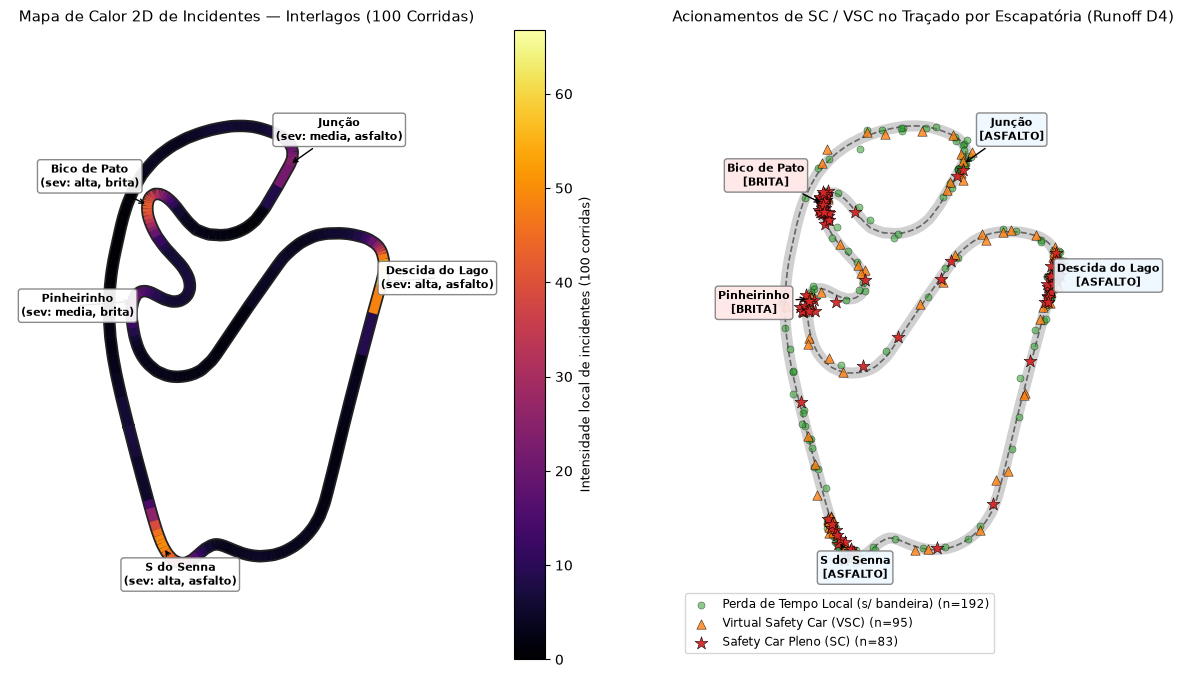

In [4]:
pts = interlagos.points
px = np.array([p["x"] for p in pts])
py = np.array([p["y"] for p in pts])
pd = np.array([p["distance_m"] for p in pts])

px_loop = np.append(px, px[0])
py_loop = np.append(py, py[0])
pd_loop = np.append(pd, float(interlagos.length_m))

def interp_xy(d_arr):
    return np.interp(d_arr, pd_loop, px_loop), np.interp(d_arr, pd_loop, py_loop)

seg_mid_d = 0.5 * (pd_loop[:-1] + pd_loop[1:])
inc_d = np.array([i.distance_m for i in inc_inter])
diff = np.abs(seg_mid_d[:, None] - inc_d[None, :])
diff = np.minimum(diff, interlagos.length_m - diff)
density = np.sum(np.exp(-0.5 * (diff / 45.0) ** 2), axis=1)

points_2d = np.array([px_loop, py_loop]).T.reshape(-1, 1, 2)
segments_2d = np.concatenate([points_2d[:-1], points_2d[1:]], axis=1)

fig, (ax_heat, ax_cons) = plt.subplots(1, 2, figsize=(15.5, 6.8))

ax_heat.plot(px_loop, py_loop, color="#222222", lw=9, solid_capstyle="round", zorder=1)
lc = LineCollection(segments_2d, cmap="inferno", norm=plt.Normalize(0, density.max()), lw=6.5, zorder=2)
lc.set_array(density)
ax_heat.add_collection(lc)
cbar = fig.colorbar(lc, ax=ax_heat, fraction=0.046, pad=0.04)
cbar.set_label("Intensidade local de incidentes (100 corridas)", fontsize=9)

offsets = {
    "S do Senna": (40, -90),
    "Descida do Lago": (135, -15),
    "Pinheirinho": (-135, -35),
    "Bico de Pato": (-140, 45),
    "Junção": (120, 60),
}
for seg in build_track_risk_profile(interlagos):
    if seg.is_braking_zone and seg.corner_name:
        mid_d = 0.5 * (seg.start_m + seg.end_m)
        cx, cy = interp_xy(mid_d)
        dx, dy = offsets.get(seg.corner_name, (50, 30))
        ax_heat.annotate(
            f"{seg.corner_name}\n(sev: {seg.severity}, {seg.runoff})",
            xy=(cx, cy),
            xytext=(cx + dx, cy + dy),
            fontsize=8,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="gray", alpha=0.92),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
            ha="center",
            zorder=5,
        )

ax_heat.set_title("Mapa de Calor 2D de Incidentes — Interlagos (100 Corridas)", fontsize=11)
ax_heat.set_aspect("equal")
ax_heat.margins(x=0.36, y=0.22)
ax_heat.axis("off")

ax_cons.plot(px_loop, py_loop, color="#d0d0d0", lw=8, solid_capstyle="round", zorder=1)
ax_cons.plot(px_loop, py_loop, color="#666666", lw=1.2, ls="--", zorder=2)

rng_jitter = np.random.default_rng(42)
style_map = {
    "TIME_LOSS": ("Perda de Tempo Local (s/ bandeira)", "tab:green", "o", 26, 0.55, 3),
    "VSC": ("Virtual Safety Car (VSC)", "tab:orange", "^", 46, 0.80, 4),
    "SC": ("Safety Car Pleno (SC)", "tab:red", "*", 95, 0.95, 5),
}

for cons_key, (label, color, marker, size, alpha, zord) in style_map.items():
    sub_d = np.array([i.distance_m for i in inc_inter if i.consequence == cons_key])
    sx, sy = interp_xy(sub_d)
    sx = sx + rng_jitter.normal(0, 8.0, size=len(sx))
    sy = sy + rng_jitter.normal(0, 8.0, size=len(sy))
    ax_cons.scatter(sx, sy, c=color, marker=marker, s=size, alpha=alpha, edgecolors="black", linewidths=0.4, label=f"{label} (n={len(sub_d)})", zorder=zord)

for seg in build_track_risk_profile(interlagos):
    if seg.is_braking_zone and seg.corner_name:
        mid_d = 0.5 * (seg.start_m + seg.end_m)
        cx, cy = interp_xy(mid_d)
        dx, dy = offsets.get(seg.corner_name, (50, 30))
        tag_color = "#ffe6e6" if seg.runoff == "brita" else "#eef7ff"
        ax_cons.annotate(
            f"{seg.corner_name}\n[{seg.runoff.upper()}]",
            xy=(cx, cy),
            xytext=(cx + dx, cy + dy),
            fontsize=8,
            fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.25", fc=tag_color, ec="gray", alpha=0.92),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
            ha="center",
            zorder=6,
        )

ax_cons.set_title("Acionamentos de SC / VSC no Traçado por Escapatória (Runoff D4)", fontsize=11)
ax_cons.set_aspect("equal")
ax_cons.margins(x=0.36, y=0.22)
ax_cons.axis("off")
ax_cons.legend(loc="lower left", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig("validacao_mapa_calor_pista_m3.png", dpi=130)
plt.show()
